<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

# 4. Modellierung

Dieses Notebook führt die Modellierungspipeline für ein Pairs-Trading-Setup aus:

- Laden des bereinigten Wide-Preispanels (`prices_wide_cleaned.csv`)
- Zeitbasierter Split in Train/Holdout (tagweise)
- Pair-Selektion (Korrelation → optional Cointegration-Filter)
- Feature-Panel (symbolbasierte technische Features) und Zusammenbau eines Pair-Datensatzes
- Label-Konstruktion (Mean-Reversion innerhalb `HORIZON`, intraday-sicher)
- Training/Kalibrierung von Klassifikationsmodellen und Holdout-Reporting
- Backtests: Baseline (fixer Entry) und ML-basierte dynamische Entry-Policy (inkl. Kosten)


In [1]:
# Zelle 1
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import TimeSeriesSplit
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    classification_report,
    precision_recall_curve,
)

from pairs_trading.eda.correlation import correlation_analysis
from pairs_trading.eda.cointegration import (
    compute_daily_cointegration,
    compute_pair_stats,
    rank_pairs,
)

from pairs_trading.features import build_feature_panel
from pairs_trading.features.technical import log_returns


In [2]:
# Zelle 2
DATA_PATH = Path("Daten") / "prices_wide_cleaned.csv"

HOLDOUT_FRACTION_DAYS = 0.20

CORR_METHOD = "pearson"
STRONG_THRESHOLD = 0.97
TOP_N_CORR_PAIRS = 200
USE_COINTEGRATION = True
COINT_P_THRESH = 0.05
MIN_OBS_PER_DAY_COINT = 60
TOP_N_FINAL_PAIRS = 20

HEDGE_WINDOW = 300
ZSCORE_WINDOW = 300
HORIZON = 30
Z_ENTRY = 2.0
REVERT_TO = 0.5

SMA_WINDOWS = (20,)
EMA_SPANS = (20,)
RSI_WINDOWS = (14,)
ROC_WINDOWS = (10,)
VOL_WINDOWS = (20,)

BB_WINDOWS = (20,)
SPREAD_RSI_W = 14
SPREAD_ROC_W = 10
SPREAD_VOL_W = 20

COST_PER_SIDE = 0.0001

USE_DYNAMIC_ENTRY_POLICY = True
P_ENTRY = 0.60
Z_MIN = 1.25

RANDOM_STATE = 42


In [3]:
# Zelle 3
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Bereinigter Datensatz nicht gefunden: {DATA_PATH}\n"
        "Bitte das Cleaning-Notebook ausführen, sodass 'Daten/prices_wide_cleaned.csv' erzeugt wird."
    )

prices_wide = pd.read_csv(DATA_PATH)

dt_col = "datetime" if "datetime" in prices_wide.columns else prices_wide.columns[0]
prices_wide[dt_col] = pd.to_datetime(prices_wide[dt_col], errors="coerce", utc=False)
prices_wide = prices_wide.dropna(subset=[dt_col]).sort_values(dt_col).set_index(dt_col)

prices_wide = prices_wide.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")
log_prices = np.log(prices_wide)

df = (
    prices_wide.stack(dropna=False)
    .rename("close")
    .reset_index()
    .rename(columns={dt_col: "datetime", "level_1": "symbol"})
)
df = df.dropna(subset=["datetime", "symbol", "close"])
df["date"] = df["datetime"].dt.floor("D")

print(f"OK: prices_wide geladen aus {DATA_PATH}")
print(f"Shape: {prices_wide.shape[0]} Zeitpunkte x {prices_wide.shape[1]} Symbole")
print(f"Index: {prices_wide.index.min()} . {prices_wide.index.max()}")


OK: prices_wide geladen aus Daten\prices_wide_cleaned.csv
Shape: 66631 Zeitpunkte x 464 Symbole
Index: 2025-11-07 14:30:00 . 2025-12-23 21:00:00


In [4]:
# Zelle 4 — Log-Preise (aus dem geladenen Wide-Panel) + kurzer Sanity-Check
# Erwartung: prices_wide kommt aus Zelle 3 (Datetime-Index, Spalten=Symbole, Werte=Close)

prices_wide = prices_wide.sort_index()

log_prices = np.log(prices_wide)

print("prices_wide shape:", prices_wide.shape)
print("log_prices shape:  ", log_prices.shape)
print("Start:", prices_wide.index.min(), "| Ende:", prices_wide.index.max())

prices_wide.iloc[:3, :3]


prices_wide shape: (66631, 464)
log_prices shape:   (66631, 464)
Start: 2025-11-07 14:30:00 | Ende: 2025-12-23 21:00:00


,A,AAPL,ABBV
datetime,,,
2025-11-07 14:30:00,145.729996,268.674988,218.285004
2025-11-07 14:31:00,NaN,268.309998,218.244995
2025-11-07 14:32:00,146.089996,267.420013,218.764999


In [5]:
# Zelle 5 — Train/Holdout Tage bestimmen (für Pair-Selection und Modellierung)
all_days = np.array(sorted(df["date"].unique()))
n_holdout = int(max(1, round(HOLDOUT_FRACTION_DAYS * len(all_days))))
cutoff_day = all_days[-n_holdout]  # Holdout startet ab cutoff_day

train_mask = df["date"] < cutoff_day
holdout_mask = df["date"] >= cutoff_day

print("Train-Tage:", int(df.loc[train_mask, "date"].nunique()))
print("Holdout-Tage:", int(df.loc[holdout_mask, "date"].nunique()))
print("Holdout ab:", cutoff_day)

# Log-Preise für Pair-Selection nur Train (verhindert Data Snooping)
log_prices_train = log_prices.loc[log_prices.index.floor("D") < cutoff_day].copy()


Train-Tage: 25
Holdout-Tage: 6
Holdout ab: 2025-12-16T00:00:00.000000000


In [6]:
# Zelle 6 — Pair-Auswahl (Korrelation → optional Cointegration → Ranking)

corr_out = correlation_analysis(
    prices_wide=log_prices_train,
    method=CORR_METHOD,
    strong_threshold=STRONG_THRESHOLD,
    plot=False,
    title=None,
)

strong_pairs = corr_out["strong_pairs"].copy()

if strong_pairs.empty:
    raise ValueError("Keine starken Paare gefunden. STRONG_THRESHOLD reduzieren.")

pairs_corr = (
    strong_pairs
    .rename(columns={"symbol_1": "symbol1", "symbol_2": "symbol2", "correlation": "corr"})
    .head(TOP_N_CORR_PAIRS)
    .reset_index(drop=True)
)

pairs_sel = pairs_corr.copy()

if USE_COINTEGRATION:
    pairs_list = list(pairs_sel[["symbol1", "symbol2"]].itertuples(index=False, name=None))

    daily_coint = compute_daily_cointegration(
        log_prices_train,
        pairs_list,
        min_obs_per_day=MIN_OBS_PER_DAY_COINT,
        sort_index=True,
        sort_symbols_in_pair=True,
        verbose=False,
    )

    if not daily_coint.empty:
        stats = compute_pair_stats(daily_coint, p_thresh=COINT_P_THRESH)
        ranked_df, _ = rank_pairs(stats)

        ranked = (
            ranked_df
            .reset_index()
            .rename(columns={"level_0": "symbol1", "level_1": "symbol2"})
        )

        ranked = ranked.merge(
            pairs_sel[["symbol1", "symbol2", "corr"]],
            on=["symbol1", "symbol2"],
            how="left",
        )

        if "mean_p" in ranked.columns:
            ranked = ranked[ranked["mean_p"] <= COINT_P_THRESH]
        elif "consistency" in ranked.columns:
            ranked = ranked[ranked["consistency"] >= 0.20]

        if not ranked.empty:
            pairs_sel = ranked.sort_values(
                "mean_p" if "mean_p" in ranked.columns else ranked.columns.tolist()
            ).reset_index(drop=True)

pairs_final_df = pairs_sel.head(TOP_N_FINAL_PAIRS).copy()
PAIRS = list(pairs_final_df[["symbol1", "symbol2"]].itertuples(index=False, name=None))

print(f"Finale Anzahl Pairs: {len(PAIRS)}")
print("Beispiele:", PAIRS[:10])


Finale Anzahl Pairs: 20
Beispiele: [('GOOG', 'GOOGL'), ('SYF', 'USB'), ('CFG', 'SYF'), ('CFG', 'USB'), ('PNC', 'TFC'), ('FITB', 'RF'), ('HBAN', 'USB'), ('GM', 'RF'), ('FOX', 'FOXA'), ('CFG', 'TFC')]


In [7]:
# Zelle 7 — Symbol-Feature-Panel aus dem Package (MultiIndex columns: feature x symbol)
# Wir bauen Features auf GESAMTDATEN (Train + Holdout) damit später Join nicht „abbricht“.
# Wichtig: Leakage vermeiden wir nicht über Feature-Berechnung, sondern über Split/Training.
# (Rolling Indikatoren sind kausal, diff/rolling nutzen nur Vergangenheit.)

feature_panel = build_feature_panel(
    log_prices,
    sma_windows=SMA_WINDOWS,
    ema_spans=EMA_SPANS,
    rsi_windows=RSI_WINDOWS,
    roc_windows=ROC_WINDOWS,
    vol_windows=VOL_WINDOWS,
    bollinger_windows=BB_WINDOWS,
)

print("Feature-Panel gebaut.")
print("Shape:", feature_panel.shape)
print("MultiIndex columns:", isinstance(feature_panel.columns, pd.MultiIndex))
feature_panel.iloc[:3, :6]


Feature-Panel gebaut.
Shape: (66631, 4176)
MultiIndex columns: True


BB_WIDTH_20                        
                              A AAPL ABBV ABNB ACGL ACN
datetime                                               
2025-11-07 14:30:00         NaN  NaN  NaN  NaN  NaN NaN
2025-11-07 14:31:00         NaN  NaN  NaN  NaN  NaN NaN
2025-11-07 14:32:00         NaN  NaN  NaN  NaN  NaN NaN

In [8]:
# Zelle 8 — Hilfsfunktionen: Pair-Block bauen (Spread, Zscore, intraday-sicheres Label) + Feature-Join
def rolling_beta(y: pd.Series, x: pd.Series, window: int) -> pd.Series:
    """
    Rolling OLS beta (ohne Intercept): beta = cov(y,x)/var(x)
    Stabil für Hedge-Ratio-Approx. in intraday.
    """
    cov = y.rolling(window).cov(x)
    var = x.rolling(window).var()
    return cov / var

def zscore(series: pd.Series, window: int) -> pd.Series:
    mu = series.rolling(window).mean()
    sd = series.rolling(window).std()
    return (series - mu) / sd

def add_spread_features(out: pd.DataFrame) -> pd.DataFrame:
    add = globals().get("ADD_SPREAD_TECH_FEATURES", True)
    if not add:
        return out

    bb_windows = globals().get("BB_WINDOWS", (20,))
    spread_rsi_w = globals().get("SPREAD_RSI_W", 14)
    spread_roc_w = globals().get("SPREAD_ROC_W", 10)
    spread_vol_w = globals().get("SPREAD_VOL_W", 20)

    s = out["spread"].copy()

    for w in bb_windows:
        ma = s.rolling(w).mean()
        sd = s.rolling(w).std(ddof=0)
        out[f"spread_bb_mid_{w}"] = ma
        out[f"spread_bb_up_{w}"] = ma + 2 * sd
        out[f"spread_bb_dn_{w}"] = ma - 2 * sd
        out[f"spread_bb_w_{w}"] = (out[f"spread_bb_up_{w}"] - out[f"spread_bb_dn_{w}"])

    delta = s.diff()
    gain = delta.clip(lower=0.0)
    loss = (-delta).clip(lower=0.0)
    avg_gain = gain.rolling(spread_rsi_w).mean()
    avg_loss = loss.rolling(spread_rsi_w).mean()
    rs = avg_gain / avg_loss.replace(0.0, np.nan)
    out[f"spread_rsi_{spread_rsi_w}"] = 100 - (100 / (1 + rs))

    out[f"spread_roc_{spread_roc_w}"] = s.pct_change(spread_roc_w)
    out[f"spread_vol_{spread_vol_w}"] = s.pct_change().rolling(spread_vol_w).std(ddof=0)

    return out
    """
    Zusätzliche, leichte Spread-Features (optional).
    """
    out = df_pair.copy()
    s = out["spread"]

    if ADD_SPREAD_TECH_FEATURES:
        # RSI (auf Spread-Delta)
        delta = s.diff()
        gain = delta.clip(lower=0.0)
        loss = (-delta).clip(lower=0.0)
        avg_gain = gain.rolling(SPREAD_RSI_W, min_periods=SPREAD_RSI_W).mean()
        avg_loss = loss.rolling(SPREAD_RSI_W, min_periods=SPREAD_RSI_W).mean()
        rs = avg_gain / avg_loss
        out[f"spread_rsi_{SPREAD_RSI_W}"] = 100.0 - (100.0 / (1.0 + rs))

        # ROC (Spread)
        out[f"spread_roc_{SPREAD_ROC_W}"] = s.diff(SPREAD_ROC_W)

        # Vol (Spread)
        out[f"spread_vol_{SPREAD_VOL_W}"] = s.diff().rolling(SPREAD_VOL_W, min_periods=SPREAD_VOL_W).std()

    return out

def flatten_features_for_symbols(feature_panel: pd.DataFrame, s1: str, s2: str) -> pd.DataFrame:
    """
    feature_panel: MultiIndex (feature, symbol)
    -> DataFrame mit Spalten: f"{feature}__s1", f"{feature}__s2"
    """
    fp = feature_panel.copy()

    if s1 not in fp.columns.get_level_values(1) or s2 not in fp.columns.get_level_values(1):
        raise ValueError(f"Symbol fehlt in feature_panel: {s1} oder {s2}")

    fp12 = fp.loc[:, (slice(None), [s1, s2])].copy()

    # columns -> FEATURE__SYMBOL
    fp12.columns = [f"{f}__{sym}" for (f, sym) in fp12.columns.to_list()]
    return fp12

def build_pair_block(
    log_prices_all: pd.DataFrame,
    feature_panel_all: pd.DataFrame,
    s1: str,
    s2: str,
    *,
    hedge_window: int,
    zscore_window: int,
    horizon: int,
    z_entry: float,
    revert_to: float,
) -> pd.DataFrame:
    """
    Baut Pair-DataFrame mit:
      - datetime, date, pair, symbol1, symbol2
      - lp1, lp2, beta, spread, zscore, z_abs
      - intraday-sicheres label y_revert (nur bei Entry-Events)
      - symbol-features für s1/s2
      - optionale spread-features

    Intraday-sicher: label nutzt groupby(date).shift(-horizon), damit kein Exit über Tagesgrenze möglich ist.
    """
    lp = log_prices_all[[s1, s2]].dropna().copy()
    if lp.empty:
        return pd.DataFrame()

    lp = lp.sort_index()
    out = pd.DataFrame(index=lp.index)
    out["lp1"] = lp[s1]
    out["lp2"] = lp[s2]

    out["date"] = out.index.floor("D")
    out["symbol1"] = s1
    out["symbol2"] = s2
    out["pair"] = f"{s1}__{s2}"

    # Hedge ratio (rolling)
    out["beta"] = rolling_beta(out["lp1"], out["lp2"], hedge_window)

    # Spread
    out["spread"] = out["lp1"] - out["beta"] * out["lp2"]

    # Zscore
    out["zscore"] = zscore(out["spread"], zscore_window)
    out["z_abs"] = out["zscore"].abs()

    # Label: nur Entry-Events, intraday-sicher (pro Tag shift)
    # z_fwd = z_{t+h} nur wenn innerhalb des gleichen Tages vorhanden
    z_fwd = out.groupby("date")["zscore"].shift(-horizon)
    entry = out["z_abs"] >= z_entry
    out["y_revert"] = np.where(entry, (z_fwd.abs() <= revert_to).astype(float), np.nan)

    # Features joinen (symbol-level)
    fp12 = flatten_features_for_symbols(feature_panel_all, s1, s2)
    out = out.join(fp12, how="left")

    # Spread Features (optional)
    out = add_spread_features(out)

    # datetime als Spalte
    out = out.reset_index().rename(columns={"index": "datetime"})

    return out


In [9]:
# Zelle 9 — ML-Dataset bauen (alle Pairs)
frames = []
for (s1, s2) in PAIRS:
    dfp = build_pair_block(
        log_prices_all=log_prices,
        feature_panel_all=feature_panel,
        s1=s1,
        s2=s2,
        hedge_window=HEDGE_WINDOW,
        zscore_window=ZSCORE_WINDOW,
        horizon=HORIZON,
        z_entry=Z_ENTRY,
        revert_to=REVERT_TO,
    )
    if not dfp.empty:
        frames.append(dfp)

ml_df = pd.concat(frames, ignore_index=True).sort_values(["datetime", "pair"]).reset_index(drop=True)

print("ML-DataFrame gebaut.")
print("Shape:", ml_df.shape)
print("Pairs:", ml_df["pair"].nunique())
ml_df.head()


[]
ML-DataFrame gebaut.
Shape: (238749, 199)
Pairs: 20


,datetime,lp1,lp2,date,symbol1,symbol2,pair,beta,spread,zscore,...,VOL_20__NXPI,BB_WIDTH_20__CTSH,EMA_20__CTSH,MACD_HIST__CTSH,MACD_LINE__CTSH,MACD_SIGNAL__CTSH,ROC_10__CTSH,RSI_14__CTSH,SMA_20__CTSH,VOL_20__CTSH
0,2025-11-07 14:30:00,3.923359,2.733068,2025-11-07,CFG,HBAN,CFG__HBAN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-11-07 14:30:00,3.923359,4.291555,2025-11-07,CFG,SYF,CFG__SYF,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-11-07 14:30:00,3.923359,3.781231,2025-11-07,CFG,TFC,CFG__TFC,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-11-07 14:30:00,3.923359,3.846738,2025-11-07,CFG,USB,CFG__USB,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-11-07 14:30:00,4.290048,3.846738,2025-11-07,CTSH,USB,CTSH__USB,NaN,NaN,NaN,...,NaN,NaN,4.290048,0.0,0.0,0.0,NaN,NaN,NaN,NaN


In [10]:
# Zelle 10 — Feature-Spalten definieren + Train/Holdout Split
target_col = "y_revert"
non_feature = {
    "datetime", "date", "pair", "symbol1", "symbol2",
    "lp1", "lp2", "beta", "spread", "zscore", "z_abs",
    target_col
}

feature_cols = [c for c in ml_df.columns if c not in non_feature]

# Nur Zeilen mit Label (Entry-Events) werden fürs Supervised-Learning genutzt.
labeled = ml_df.dropna(subset=[target_col]).copy()

train = labeled[labeled["date"] < cutoff_day].copy()
holdout = labeled[labeled["date"] >= cutoff_day].copy()

X_train = train[feature_cols]
y_train = train[target_col].astype(int)

X_hold = holdout[feature_cols]
y_hold = holdout[target_col].astype(int)

print("Labelled Samples:", len(labeled))
print("Train:", len(train), "| Holdout:", len(holdout))
print("Positiv-Rate Train:", y_train.mean().round(4), "| Holdout:", y_hold.mean().round(4))


Labelled Samples: 40692
Train: 33141 | Holdout: 7551
Positiv-Rate Train: 0.0216 | Holdout: 0.0208


In [11]:
# Zelle 11 — Baseline (fixes Z_ENTRY) + PnL-Logik inkl. Transaktionskosten (intraday-sicher)
def backtest_baseline_fixed_entry(
    df_all: pd.DataFrame,
    *,
    horizon: int,
    z_entry: float,
    cost_per_side: float,
) -> pd.DataFrame:
    """
    Baseline-Backtest:
      - Entry: |z| >= z_entry
      - Exit: nach horizon Bars (intraday-sicher via groupby(date).shift)
      - Direction: z>0 => short spread, z<0 => long spread
      - PnL ~ -direction * (spread_exit - spread_entry)
      - Kosten: 2 * cost_per_side (Roundtrip)
    """
    d = df_all.copy()
    d = d.sort_values(["pair", "datetime"]).reset_index(drop=True)

    d["spread_exit"] = d.groupby(["pair", "date"])["spread"].shift(-horizon)
    d["is_horizon_safe"] = d["spread_exit"].notna()

    d["entry"] = (d["zscore"].abs() >= z_entry) & d["is_horizon_safe"]

    d["direction"] = np.where(d["zscore"] > 0, -1.0, +1.0)

    d["gross_pnl"] = d["direction"] * (d["spread_exit"] - d["spread"])
    d["cost"] = np.where(d["entry"], 2.0 * cost_per_side, 0.0)
    d["net_pnl"] = np.where(d["entry"], d["gross_pnl"] - d["cost"], 0.0)

    pnl_ts = (
        d.groupby("datetime")[["gross_pnl", "net_pnl", "entry"]]
         .sum()
         .rename(columns={"entry": "n_trades"})
         .reset_index()
         .sort_values("datetime")
    )
    pnl_ts["cum_net_pnl"] = pnl_ts["net_pnl"].cumsum()
    pnl_ts["cum_gross_pnl"] = pnl_ts["gross_pnl"].cumsum()
    return pnl_ts

baseline_all = backtest_baseline_fixed_entry(
    df_all=ml_df.loc[ml_df["date"] >= cutoff_day].copy(),
    horizon=HORIZON,
    z_entry=Z_ENTRY,
    cost_per_side=COST_PER_SIDE,
)

print("Baseline fertig.")
baseline_all.tail()


Baseline fertig.


,datetime,gross_pnl,net_pnl,n_trades,cum_net_pnl,cum_gross_pnl
2341,2025-12-23 20:56:00,0.0,0.0,0,-2153.327137,-1397.051827
2342,2025-12-23 20:57:00,0.0,0.0,0,-2153.327137,-1397.051827
2343,2025-12-23 20:58:00,0.0,0.0,0,-2153.327137,-1397.051827
2344,2025-12-23 20:59:00,0.0,0.0,0,-2153.327137,-1397.051827
2345,2025-12-23 21:00:00,0.0,0.0,0,-2153.327137,-1397.051827


In [12]:
# Zelle 12 — Modelle (mehrere Learner) + TimeSeries-CV auf Train, dann Holdout
# Hinweis: Wir kalibrieren die Modelle, damit p(y=1) sinnvoll als Trading-Policy genutzt werden kann.

pos = float(y_train.sum())
neg = float(len(y_train) - y_train.sum())
scale_pos_weight = (neg / pos) if pos > 0 else 1.0

models = {
    "LogReg": LogisticRegression(
        solver="saga",          # robuste Konvergenz bei vielen/korrelierten Features
        penalty="l2",
        max_iter=5000,          # deutlich höher, damit ConvergenceWarning wegfällt
        tol=1e-3,               # etwas großzügiger (schneller/stabiler), ohne Warnings zu "ignorieren"
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "XGB": XGBClassifier(
        n_estimators=600,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="auc",
        tree_method="hist",
        scale_pos_weight=scale_pos_weight,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "RF": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        max_depth=None,
        min_samples_leaf=5,
    ),
}

calib_cv = TimeSeriesSplit(n_splits=3)

pipelines = {}
for name, clf in models.items():
    base = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler(with_mean=True, with_std=True)),
        ("clf", clf),
    ])

    calibrated = CalibratedClassifierCV(
        estimator=base,         # (neuere sklearn) – falls du sehr alte sklearn hast: base_estimator=base
        method="sigmoid",
        cv=calib_cv,
        n_jobs=-1,
    )
    pipelines[name] = calibrated

train_sorted = train.sort_values(["datetime"]).reset_index(drop=True)
Xtr = train_sorted[feature_cols]
ytr = train_sorted[target_col]

outer_cv = TimeSeriesSplit(n_splits=3)

cv_rows = []
for name, model in pipelines.items():
    aucs, aps = [], []
    for tr_idx, va_idx in outer_cv.split(Xtr):
        m = clone(model)
        m.fit(Xtr.iloc[tr_idx], ytr.iloc[tr_idx])
        p = m.predict_proba(Xtr.iloc[va_idx])[:, 1]
        aucs.append(roc_auc_score(ytr.iloc[va_idx], p))
        aps.append(average_precision_score(ytr.iloc[va_idx], p))

    cv_rows.append({
        "model": name,
        "cv_auc_mean": float(np.mean(aucs)),
        "cv_auc_std": float(np.std(aucs)),
        "cv_ap_mean": float(np.mean(aps)),
        "cv_ap_std": float(np.std(aps)),
    })

cv_df = (
    pd.DataFrame(cv_rows)
      .sort_values("cv_auc_mean", ascending=False)
      .reset_index(drop=True)
)

print("CV-Ergebnisse (Train):")
display(cv_df)

best_model_name = cv_df.loc[0, "model"]
best_model = pipelines[best_model_name]

best_model.fit(X_train, y_train)
p_hold = best_model.predict_proba(X_hold)[:, 1]

print(f"Bestes Modell (nach CV AUC): {best_model_name}")
print("Holdout AUC:", roc_auc_score(y_hold, p_hold).round(4))
print("Holdout AP:", average_precision_score(y_hold, p_hold).round(4))


CV-Ergebnisse (Train):


,model,cv_auc_mean,cv_auc_std,cv_ap_mean,cv_ap_std
0,XGB,0.565218,0.029278,0.021236,0.004463
1,LogReg,0.552103,0.040054,0.022521,0.002197
2,RF,0.494258,0.024791,0.018238,0.003556


Bestes Modell (nach CV AUC): XGB
Holdout AUC: 0.5877
Holdout AP: 0.0283


Holdout — Positivrate (Base rate): 0.020792
Holdout — p_hold min/max: 0.016179 / 0.020974
Holdout — Average Precision (AP): 0.028265 | AP / Base rate: 1.359


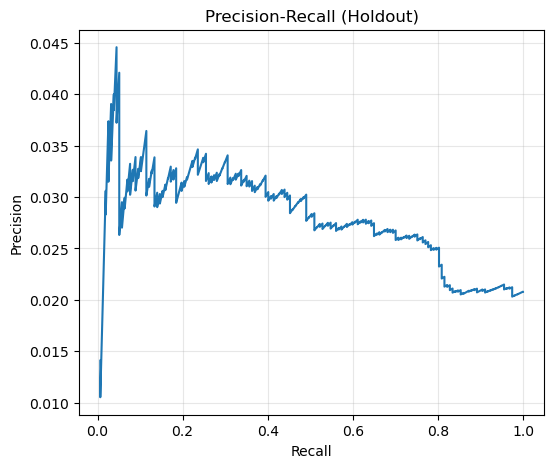


Klassifikationsbericht (Holdout, Schwelle = 99%-Quantil aus TRAIN-Scores, thr=0.020077):
              precision    recall  f1-score   support

           0      0.979     0.997     0.988      7394
           1      0.000     0.000     0.000       157

    accuracy                          0.976      7551
   macro avg      0.490     0.498     0.494      7551
weighted avg      0.959     0.976     0.967      7551


Klassifikationsbericht (Holdout, F1-optimale Schwelle aus TRAIN, thr=0.019392):
              precision    recall  f1-score   support

           0      0.980     0.979     0.979      7394
           1      0.043     0.045     0.044       157

    accuracy                          0.959      7551
   macro avg      0.511     0.512     0.512      7551
weighted avg      0.960     0.959     0.960      7551



In [13]:
# Zelle 13 — Reporting: AP/PR (imbalance-robust) + sinnvolle Schwellenwahl

base_rate = float(np.mean(y_hold))
p_min, p_max = float(np.min(p_hold)), float(np.max(p_hold))
ap = average_precision_score(y_hold, p_hold)

print("Holdout — Positivrate (Base rate):", round(base_rate, 6))
print("Holdout — p_hold min/max:", round(p_min, 6), "/", round(p_max, 6))
print("Holdout — Average Precision (AP):", round(float(ap), 6), "| AP / Base rate:", round(float(ap / base_rate), 3))

prec_h, rec_h, _ = precision_recall_curve(y_hold, p_hold)
mask = rec_h > 0
plt.figure(figsize=(6, 5))
plt.plot(rec_h[mask], prec_h[mask])
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall (Holdout)")
plt.grid(True, alpha=0.3)
plt.show()

p_train = best_model.predict_proba(X_train)[:, 1]

q = 0.99
thr_q = float(np.quantile(p_train, q))
y_pred_q = (p_hold >= thr_q).astype(int)

print(f"\nKlassifikationsbericht (Holdout, Schwelle = {q:.0%}-Quantil aus TRAIN-Scores, thr={thr_q:.6f}):")
print(classification_report(y_hold, y_pred_q, digits=3, zero_division=0))

prec_t, rec_t, ths_t = precision_recall_curve(y_train, p_train)
f1_t = 2 * (prec_t * rec_t) / (prec_t + rec_t + 1e-12)
best_idx_t = int(np.nanargmax(f1_t))
thr_f1 = float(ths_t[max(best_idx_t - 1, 0)])
y_pred_f1 = (p_hold >= thr_f1).astype(int)

print(f"\nKlassifikationsbericht (Holdout, F1-optimale Schwelle aus TRAIN, thr={thr_f1:.6f}):")
print(classification_report(y_hold, y_pred_f1, digits=3, zero_division=0))


In [15]:
# Zelle 14 — Dynamische Entry-Policy (ML) + Backtest inkl. Kosten

def backtest_ml_dynamic_entry(
    df_all: pd.DataFrame,
    model,
    feature_cols: list[str],
    *,
    horizon: int,
    p_entry=None,
    p_entry_quantile=None,
    z_min: float,
    cost_per_side: float,
) -> pd.DataFrame:
    if (p_entry is None) == (p_entry_quantile is None):
        raise ValueError("Gib genau eine der beiden Optionen an: p_entry ODER p_entry_quantile.")

    d = df_all.copy()
    d = d.sort_values(["pair", "datetime"]).reset_index(drop=True)

    d["spread_exit"] = d.groupby(["pair", "date"])["spread"].shift(-horizon)
    d["is_horizon_safe"] = d["spread_exit"].notna()

    X = d[feature_cols]
    d["p_revert"] = model.predict_proba(X)[:, 1]

    if p_entry_quantile is not None:
        d["_p_for_thr"] = d["p_revert"].where(d["is_horizon_safe"])
        d["thr"] = (
            d.groupby("pair", group_keys=False)["_p_for_thr"]
             .apply(lambda s: s.expanding().quantile(p_entry_quantile).shift(1))
        )
        d.drop(columns=["_p_for_thr"], inplace=True)
    else:
        d["thr"] = float(p_entry)

    d["entry"] = (
        d["thr"].notna()
        & (d["p_revert"] >= d["thr"])
        & (d["z_abs"] >= z_min)
        & d["is_horizon_safe"]
    )

    d["direction"] = np.where(d["zscore"] > 0, -1.0, +1.0)
    d["gross_pnl"] = d["direction"] * (d["spread_exit"] - d["spread"])
    d["cost"] = np.where(d["entry"], 2.0 * cost_per_side, 0.0)
    d["net_pnl"] = np.where(d["entry"], d["gross_pnl"] - d["cost"], 0.0)

    pnl_ts = (
        d.groupby("datetime")[["gross_pnl", "net_pnl", "entry"]]
         .sum()
         .rename(columns={"entry": "n_trades"})
         .reset_index()
         .sort_values("datetime")
    )

    pnl_ts["cum_net_pnl"] = pnl_ts["net_pnl"].cumsum()
    pnl_ts["cum_gross_pnl"] = pnl_ts["gross_pnl"].cumsum()
    return pnl_ts



if USE_DYNAMIC_ENTRY_POLICY:
    ml_curves = {}

    df_bt = ml_df.loc[ml_df["date"] >= cutoff_day].copy()

    for name, model in pipelines.items():
        model.fit(X_train, y_train)

        curve = backtest_ml_dynamic_entry(
            df_all=df_bt,
            model=model,
            feature_cols=feature_cols,
            horizon=HORIZON,
            p_entry_quantile=0.99,
            z_min=Z_MIN,
            cost_per_side=COST_PER_SIDE,
        )

        if curve is not None and len(curve) > 0:
            ml_curves[name] = curve

    print(f"ML-Policy Backtests fertig. Modelle: {list(ml_curves.keys())}")
else:
    ml_curves = {}


ML-Policy Backtests fertig. Modelle: ['LogReg', 'XGB', 'RF']


Trades (Baseline): 6741


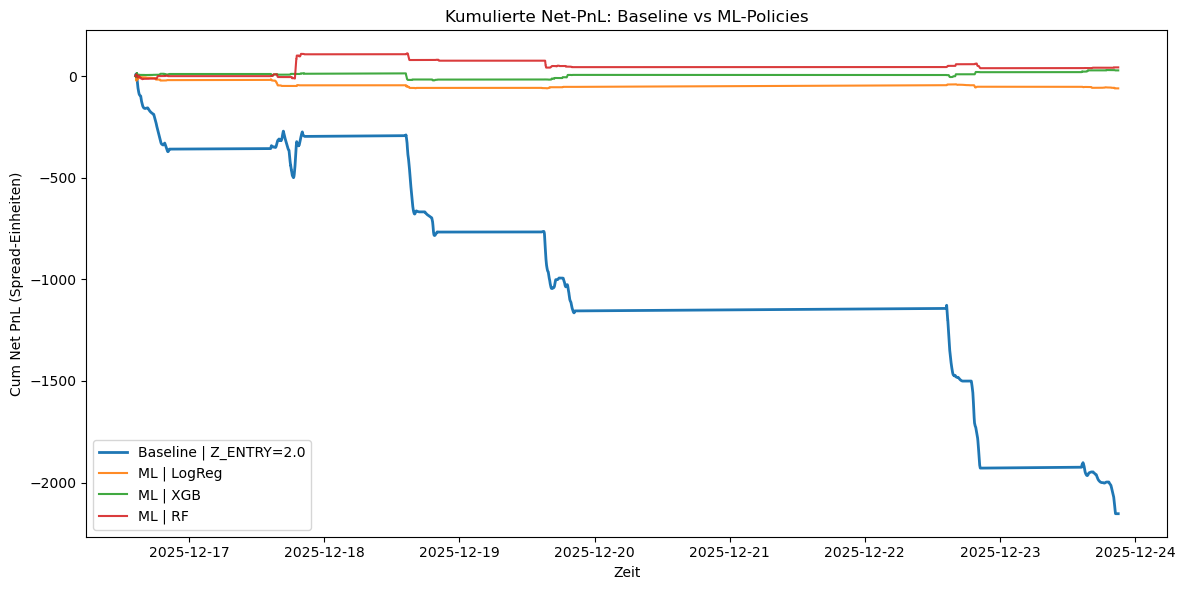

,model,trades,final_cum_net_pnl
0,RF,485,43.056334
1,XGB,382,28.320474
2,LogReg,463,-60.162932


In [16]:
# Zelle 15 — Vergleich: Baseline vs alle ML-Policies in einem Plot

plt.figure(figsize=(12, 6))

plt.plot(
    baseline_all["datetime"],
    baseline_all["cum_net_pnl"],
    label=f"Baseline | Z_ENTRY={Z_ENTRY}",
    linewidth=2,
)

print("Trades (Baseline):", int(baseline_all["n_trades"].sum()))

summary_rows = []

if USE_DYNAMIC_ENTRY_POLICY and len(ml_curves) > 0:
    for name, curve in ml_curves.items():
        plt.plot(
            curve["datetime"],
            curve["cum_net_pnl"],
            label=f"ML | {name}",
            alpha=0.9,
        )

        trades = int(curve["n_trades"].sum()) if "n_trades" in curve.columns else np.nan
        final_pnl = float(curve["cum_net_pnl"].iloc[-1])

        summary_rows.append({
            "model": name,
            "trades": trades,
            "final_cum_net_pnl": final_pnl,
        })

plt.title("Kumulierte Net-PnL: Baseline vs ML-Policies")
plt.xlabel("Zeit")
plt.ylabel("Cum Net PnL (Spread-Einheiten)")
plt.legend()
plt.tight_layout()
plt.show()

if len(summary_rows) > 0:
    summary_df = (
        pd.DataFrame(summary_rows)
          .sort_values("final_cum_net_pnl", ascending=False)
          .reset_index(drop=True)
    )
    display(summary_df)


<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="03_Explorative_Datenanalyse.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="05_.html">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
